In [1]:
%%time
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,make_union
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.feature_selection import RFECV
from sklearn.metrics import mean_absolute_error, mean_squared_error, make_scorer
from sklearn.model_selection import cross_val_score, KFold, learning_curve

warnings.filterwarnings('ignore')

Wall time: 6.4 s


In [2]:
df=pd.read_csv("training_dataset.csv")
df.drop(["region__peak_sales_dollar_amt_per_hour_v2","region__peak_returns_dollar_amt_per_hour_v2","Unnamed: 0","observation_id","observation_timestamp"], axis=1, inplace=True)
df.head()

,hour_of_day,register__sales_dollar_amt_this_hour,register__payment_types_accepted,register__peak_sales_dollar_amt_per_hour,register__sales_dollar_amt_last_hour,register__sales_quantity_last_hour,register__sales_quantity_rescanned_frac,register__sales_payments_declined_frac,register__peak_returns_dollar_amt_per_hour,register__returns_dollar_amt_last_hour,...,region__mean_service_time_per_customer,region__stdev_service_time_per_customer,region__sales_dollar_amt_last_hour,region__returns_dollar_amt_last_hour,region__nighttime_open_registers,region__nighttime_service_time_per_customer,region__nighttime_sales_amt_per_hour,region__nighttime_returns_amt_per_hour,region__peak_sales_dollar_amt_per_hour,region__peak_returns_dollar_amt_per_hour
0,15,347.29,Cash+Credit,-0.7383,-0.1270,-0.1993,-0.8299,-0.1247,-0.5721,-0.2582,...,-0.9255,-0.3891,-0.6920,-0.4605,-0.5180,-1.0062,-0.6462,-0.6030,-0.4773,-1.7951
1,21,361.59,Cash+Credit,0.6483,-0.0362,-0.0777,-0.7395,-0.1135,-0.5251,-0.2157,...,0.7815,0.0663,-0.6531,-0.4434,-0.6498,0.9031,-0.6493,-0.6106,0.4998,0.8939
2,11,850.73,Cash+Credit,-0.4950,-0.1268,-0.1974,1.3139,0.1075,-0.5251,-0.2579,...,-1.2559,-0.4826,-0.6120,-0.1786,-0.6040,-1.4229,-0.6456,-0.6037,1.9337,2.4046
3,10,1175.69,Cash+Credit,-0.5594,-0.1270,-0.1991,-0.8299,-0.1247,-0.5251,-0.2582,...,-1.2280,-0.4809,-0.5472,0.1246,-0.5925,-1.4097,-0.6478,-0.6079,0.1288,-0.4983
4,14,3204.53,Cash+Credit,0.5693,-0.1221,-0.1632,-0.7071,-0.1247,0.7604,-0.2565,...,0.2442,-0.3021,-0.3838,0.1996,-0.5696,1.1231,-0.6475,-0.6032,1.0050,1.5660


In [3]:
def regression_accuracy(y_meas, y_pred, max_error=20, error_type='relative'):
    '''Compares predicted & measured values, returning the percentage of predictions
       that are within a set error limit. This error limit can be an absolute value
       or a relative percentage'''

    # OPTION 1: Relative percentage
    if ( error_type == 'relative' ):
        mask = 100.0 * abs((y_pred - y_meas) / y_meas) < max_error

    # OPTION 2: Absolute value
    if ( error_type == 'absolute' ):
        mask = abs(y_pred - y_meas) < max_error

    accuracy = sum(mask) / len(mask)

    return accuracy


scorer=make_scorer(regression_accuracy)

In [4]:
def imputation(df):
    return df

In [5]:
def encodage(df):
    return df

In [6]:
def pre_processing(df):
    #df=imputation(df)
    df=encodage(df)

    if "register__sales_dollar_amt_this_hour" in df.columns.values:
        X = df.drop("register__sales_dollar_amt_this_hour", axis=1)
        y = df.register__sales_dollar_amt_this_hour
        return X,y
    else:
        X = df
        return X

In [7]:
def make_model(df, estimator=RandomForestRegressor(random_state=0)):
    numerical_features=df.select_dtypes(["float","int"]).columns
    categorical_features=df.select_dtypes("object").columns

    numerical_pipeline=make_pipeline(StandardScaler())
    categorical_pipeline=make_pipeline(OneHotEncoder(handle_unknown='ignore'))

    process=make_column_transformer((numerical_pipeline, numerical_features), (categorical_pipeline, categorical_features))

    model=make_pipeline(process, estimator)

    return model

In [8]:
# train, test= train_test_split(df[df.select_dtypes(["float","int"]).columns], random_state=25, test_size=0.5)
# X_tr, y_tr = pre_processing(train)
# model = make_model(X_tr, estimator=RandomForestRegressor(random_state=0))
# selector=RFECV(
#     RandomForestRegressor(random_state=100),
#     step=1,
#     min_features_to_select=5,
#     cv=4,
#     n_jobs=-1,
#     scoring=scorer
# )
# selector.fit(X_tr,y_tr)

# used_columns=list(X_tr.columns[selector.get_support()])
# used_columns.append("register__sales_dollar_amt_this_hour")

In [ ]:
used_columns=[
    "register__peak_sales_dollar_amt_per_hour",
    "register__sales_quantity_rescanned_frac",
    "cashier__title_level",
    "cashier__n_years_experience",
    "cashier__hours_into_shift",
    "cashier__item_scan_rate_per_min",
    "cashier__item_manual_entry_rate_per_min",
    "store__miles_to_nearest_location",
    "store__target_sales_quantity_per_hour",
    "store__mean_service_time_per_customer",
    "store__n_employees_total",
    "store__n_open_registers",
    "store__occupancy_checkout_areas",
    "store__occupancy_backrooms",
    "store__occupancy_outdoors",
    "store__parking_lot_utilization",
    "store__shelf_freespace_frac",
    "store__hrs_since_last_delivery",
    "store__returns_quantity_last_hour",
    "store__gift_returns_quantity_last_hour",
    "region__n_stores",
    "region__mean_service_time_per_customer",
    "region__sales_dollar_amt_last_hour",
    "region__returns_dollar_amt_last_hour",
    "region__nighttime_open_registers",
    "region__nighttime_service_time_per_customer",
    "region__nighttime_returns_amt_per_hour",
    "region__peak_sales_dollar_amt_per_hour",
    "region__peak_returns_dollar_amt_per_hour",
]

In [10]:
#used_columns.extend(df.select_dtypes("object").columns)
#used_columns.append("store__type_code")
train_df=df[used_columns]
train,test=train_test_split(train_df, test_size=0.2)
X_train,y_train=pre_processing(train)
X_test,y_test=pre_processing(test)

In [11]:
train_df.shape

(18512, 30)

In [12]:
def evaluation(model):

    N, train_score, val_score = learning_curve(
                                    model, X_train, y_train, cv=5,
                                    scoring=scorer,n_jobs=-1,
                                    train_sizes=np.linspace(0.1,1,10)
                                )
    
    plt.figure(figsize=(12,8))
    plt.plot(N, train_score.mean(axis=1), label='train score')
    plt.plot(N, val_score.mean(axis=1), label="validation score")
    plt.legend()

In [91]:
estimator=ExtraTreesRegressor(random_state=21)

model=make_model(X_train, estimator)

cv=KFold(n_splits=5)
scores=cross_val_score(model, X_train, y_train, cv=cv, scoring=scorer, n_jobs=-1)
print(f"CV_SCORES_mean: {scores.mean()}")
print(f"CV_SCORES_std: {scores.std()}")

CV_SCORES_mean: 0.8617732069913602
CV_SCORES_std: 0.005268571642191788


In [92]:
%%time

hyper_params = {
    'extratreesregressor__max_depth': range(3,20),
    'extratreesregressor__min_samples_split': range(4,20),
    'extratreesregressor__max_features': range(4, 20),
    'extratreesregressor__n_estimators': [10,20,30,50,80,100,200,500,1000],
}
grid=RandomizedSearchCV(model,hyper_params,n_iter=50,scoring=scorer,cv=5,n_jobs=-1,random_state=0, return_train_score=True)
#grid.fit(X_train, y_train)

Wall time: 7min 40s


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('columntransformer',
                                              ColumnTransformer(transformers=[('pipeline-1',
                                                                               Pipeline(steps=[('standardscaler',
                                                                                                StandardScaler())]),
                                                                               Index(['register__peak_sales_dollar_amt_per_hour',
       'register__sales_quantity_rescanned_frac', 'cashier__title_level',
       'cashier__n_years_experience', 'cashier__hours_into_shift',
       'cashi...
                                              ExtraTreesRegressor(random_state=21))]),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'extratreesregressor__max_depth': range(3, 20),
                                        'extratreesregressor__max_features': ran

In [93]:
grid.best_score_

0.8696063682702956

In [94]:
grid.best_params_

{'extratreesregressor__n_estimators': 1000,
 'extratreesregressor__min_samples_split': 7,
 'extratreesregressor__max_features': 9,
 'extratreesregressor__max_depth': 19}

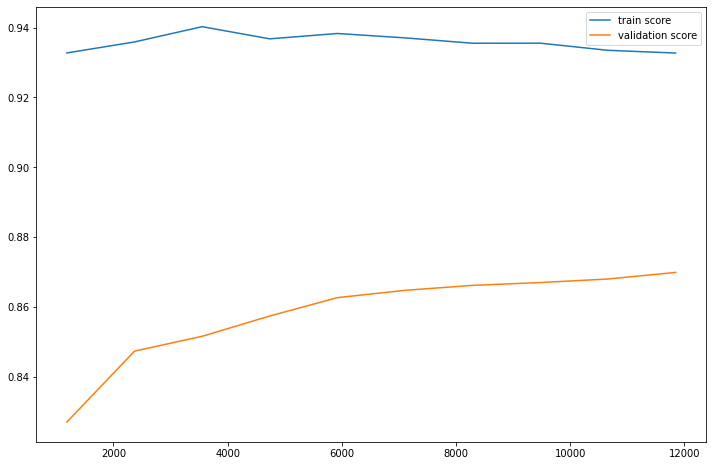

In [95]:
estimator=ExtraTreesRegressor(random_state=21, n_estimators=1000, min_samples_split=7, max_features=9, max_depth=19)
best_model=make_model(X_train, estimator)

evaluation(best_model)

In [13]:
X=train_df.drop("register__sales_dollar_amt_this_hour", axis=1)
y=train_df.register__sales_dollar_amt_this_hour

In [97]:
best_model.fit(X,y)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['register__peak_sales_dollar_amt_per_hour',
       'register__sales_quantity_rescanned_frac', 'cashier__title_level',
       'cashier__n_years_experience', 'cashier__hours_into_shift',
       'cashier__item_scan_rate_per_min',
       'cashi...
       'region__nighttime_returns_amt_per_hour',
       'region__peak_sales_dollar_amt_per_hour',
       'region__peak_returns_dollar_amt_per_hour'],
      dtype='object')),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignor

In [15]:
test_df=pd.read_csv("test_dataset.csv")
test_df.drop(["region__peak_sales_dollar_amt_per_hour_v2","region__peak_returns_dollar_amt_per_hour_v2"], axis=1, inplace=True)
test_df.head()

,observation_id,observation_timestamp,hour_of_day,register__payment_types_accepted,register__peak_sales_dollar_amt_per_hour,register__sales_dollar_amt_last_hour,register__sales_quantity_last_hour,register__sales_quantity_rescanned_frac,register__sales_payments_declined_frac,register__peak_returns_dollar_amt_per_hour,...,region__mean_service_time_per_customer,region__stdev_service_time_per_customer,region__sales_dollar_amt_last_hour,region__returns_dollar_amt_last_hour,region__nighttime_open_registers,region__nighttime_service_time_per_customer,region__nighttime_sales_amt_per_hour,region__nighttime_returns_amt_per_hour,region__peak_sales_dollar_amt_per_hour,region__peak_returns_dollar_amt_per_hour
0,3f483640-bc52-11ec-b736-8544dc068949,15/04/2022 00:23,0,Cash+Credit,0.5693,-0.1253,-0.1489,-0.8176,-0.1066,0.9103,...,-0.1320,0.3398,-0.6373,-0.3791,-0.5581,-0.7148,-0.6487,-0.6091,1.0020,0.8761
1,a88b0bb0-d2ae-11ec-bd0e-f5a7c7895456,13/05/2022 11:20,11,Cash+Credit,0.3084,-0.1270,-0.1986,1.6562,-0.1247,-0.5251,...,0.8413,0.1972,-0.6483,-0.4419,-0.6498,0.8867,-0.6493,-0.6106,-1.9779,-0.1311
2,90611780-d607-11ec-a5d8-675445c92326,17/05/2022 17:34,17,Cash+Credit,-0.6757,0.1925,0.2534,-0.7517,-0.1247,-0.5251,...,-0.3185,-0.4461,0.6712,0.3971,2.0094,0.0464,1.8275,2.0689,0.0332,-0.3489
3,a98380e0-e2d2-11ec-b28f-7f4d381958ee,03/06/2022 00:18,0,Cash+Credit,-0.1747,-0.1258,-0.1709,-0.3576,-0.1247,-0.5251,...,0.8032,0.1548,-0.6653,-0.4437,-0.6498,0.8937,-0.6493,-0.6106,0.4998,0.8939
4,608b8e60-e4f2-11ec-8115-d3258731976b,05/06/2022 17:10,17,Cash+Credit,0.6483,-0.0612,-0.0995,0.1060,-0.1247,-0.5251,...,0.9011,0.1806,-0.6495,-0.4418,-0.6498,0.9006,-0.6493,-0.6106,0.4998,0.8939


In [16]:
test_df=test_df[X.columns]
predictions = pd.DataFrame(estimator.predict(test_df), columns=["prediction"])
predictions.head()

,prediction
0,1845.079773
1,360.296691
2,1405.368534
3,225.982503
4,362.258742


In [206]:
predictions.to_csv("submit.csv", index=False)